# <center> **Proyecto visión por computador:** Comparación de modelos y elección del campeón </center>

**Por:** María José Bernal, Alejandro Olivares, Santiago Zapata y Jerly Alejandra Galeano

Este notebook reúne los resultados que dejó cada notebook de modelo en `artifacts/`, los compara con las mismas métricas y elige el campeón que usará la app de despliegue. No entrena ni vuelve a predecir nada, solo lee los artefactos guardados.

**Criterio de elección.** Gana el modelo con mayor métrica principal en **validación** con el posprocesado completo (variante C). La prueba no participa en la decisión y su resultado es el que se reporta.

**Cambio manual.** Si se quiere desplegar otro modelo, basta con poner su nombre en `CHAMPION_MANUAL` (por ejemplo `"unet_r34"`) y volver a correr el notebook. También se puede editar a mano el campo `modelo` de `artifacts/champion.json`, que es lo único que lee la app.

## 1. Configuración

In [1]:
import sys
import json
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["jpeg"]
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from config import ARTIFACTS_DIR, CHAMPION_JSON, COLORES, LABELS, METRICA_PRINCIPAL, MODELOS
from metricas import NOMBRES_METRICAS, bootstrap, promedio, tabla

CHAMPION_MANUAL = None
NOMBRE_METRICA = NOMBRES_METRICAS[METRICA_PRINCIPAL]
print(f"Métrica principal: {NOMBRE_METRICA}")

Métrica principal: Dice global


## 2. Modelos con resultados

In [2]:
resumenes, conteos, historiales = {}, {}, {}
for m in MODELOS:
    carpeta = ARTIFACTS_DIR / m
    if not (carpeta / "resumen.json").exists():
        print(f"Sin resultados todavía: {m}")
        continue
    resumenes[m] = json.loads((carpeta / "resumen.json").read_text())
    conteos[m] = dict(np.load(carpeta / "conteos.npz"))
    historiales[m] = pd.read_csv(carpeta / "historial.csv")
assert resumenes, "No hay modelos evaluados en artifacts/. Ejecuta antes los notebooks 01 a 04."
print(f"Modelos con resultados: {[MODELOS[m] for m in resumenes]}")

Modelos con resultados: ['CNN Segmenter', 'Attention Residual U-Net', 'U-Net + ResNet34', 'DeepLabV3+ + ResNet34']


## 3. Tabla comparativa
Todas las métricas se calculan sobre 350x525, sin el relleno. La validación sirve para elegir y la prueba para reportar. Las métricas por imagen miden si el modelo detecta la presencia de cada clase en la imagen, sin importar dónde.

In [3]:
filas = []
for m, r in resumenes.items():
    fila = {"Modelo": MODELOS[m], "Parámetros (M)": r["n_params"] / 1e6, "Mejor época": r["mejor_epoca"],
            f"{NOMBRE_METRICA} validación (C)": promedio(conteos[m]["val_C"], METRICA_PRINCIPAL)}
    for v in "ABC":
        fila[f"{NOMBRE_METRICA} prueba ({v})"] = promedio(conteos[m][f"test_{v}"], METRICA_PRINCIPAL)
    for met, nombre in NOMBRES_METRICAS.items():
        if met != METRICA_PRINCIPAL:
            fila[f"{nombre} prueba (C)"] = promedio(conteos[m]["test_C"], met)
    fila["ms por imagen en CPU"] = r.get("ms_por_imagen_cpu")
    filas.append(fila)

comparacion = pd.DataFrame(filas).set_index("Modelo")
comparacion = comparacion.sort_values(f"{NOMBRE_METRICA} validación (C)", ascending=False)
comparacion.to_csv(ARTIFACTS_DIR / "comparacion.csv")
comparacion.round(4).T

Modelo,DeepLabV3+ + ResNet34,U-Net + ResNet34,Attention Residual U-Net,CNN Segmenter
Parámetros (M),22.4382,24.4368,8.2026,6.9798
Mejor época,12.0000,12.0000,12.0000,12.0000
Dice global validación (C),0.6151,0.6119,0.5808,0.5532
Dice global prueba (A),0.6245,0.6191,0.5909,0.5608
Dice global prueba (B),0.6242,0.6199,0.5923,0.5624
Dice global prueba (C),0.6243,0.6201,0.5942,0.5652
IoU global prueba (C),0.4564,0.4523,0.4261,0.3987
Dice de la competencia prueba (C),0.6257,0.6233,0.5945,0.5444
Precisión por píxel prueba (C),0.5956,0.5826,0.5648,0.5286
Recall por píxel prueba (C),0.6605,0.6644,0.6273,0.6086


## 4. Resultado por clase en prueba

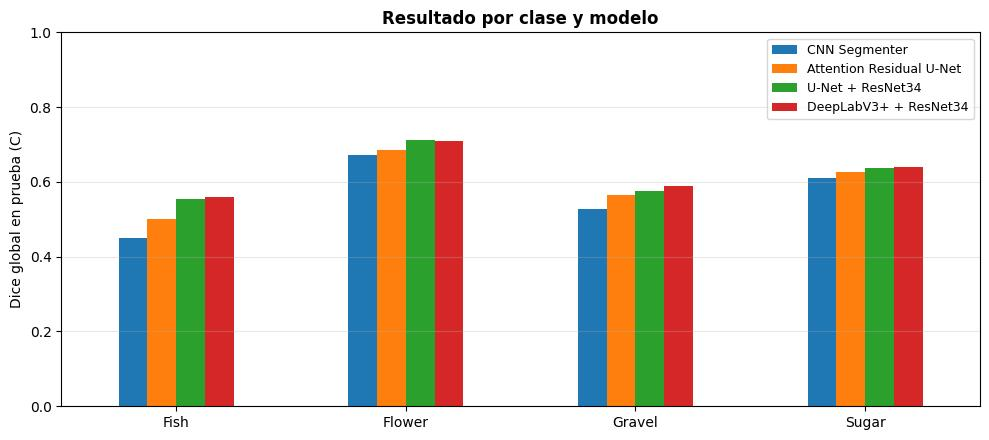

,CNN Segmenter,Attention Residual U-Net,U-Net + ResNet34,DeepLabV3+ + ResNet34
Fish,0.4490,0.5010,0.5538,0.5587
Flower,0.6721,0.6852,0.7127,0.7105
Gravel,0.5286,0.5646,0.5762,0.5880
Sugar,0.6111,0.6260,0.6375,0.6401


In [4]:
por_clase = pd.DataFrame({MODELOS[m]: tabla(conteos[m]["test_C"]).loc[METRICA_PRINCIPAL, LABELS] for m in resumenes})
fig, ax = plt.subplots(figsize=(10, 4.5))
por_clase.plot.bar(ax=ax, rot=0)
ax.set_ylabel(f"{NOMBRE_METRICA} en prueba (C)")
ax.set_ylim(0, 1)
ax.set_title("Resultado por clase y modelo", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "comparacion_por_clase.png", dpi=120)
plt.show()
por_clase.round(4)

## 5. Curvas de validación
Métrica principal en validación por época, con umbral 0.5 y sin posprocesado.

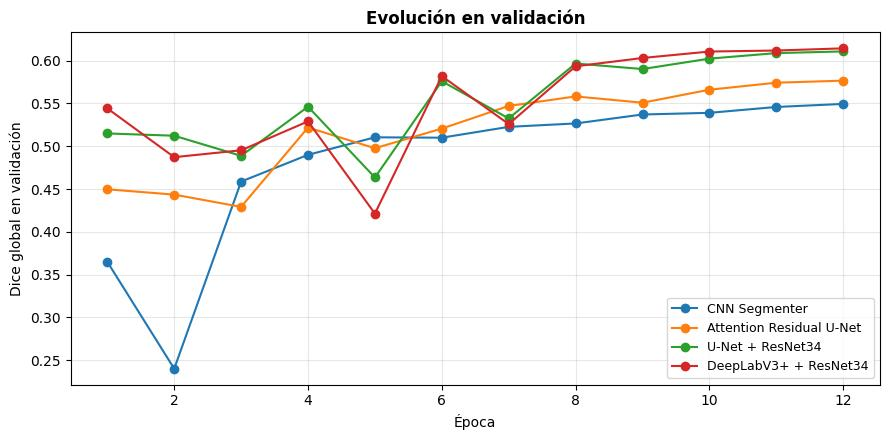

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for m, h in historiales.items():
    ax.plot(h["epoca"], h[METRICA_PRINCIPAL], marker="o", label=MODELOS[m])
ax.set_xlabel("Época")
ax.set_ylabel(f"{NOMBRE_METRICA} en validación")
ax.set_title("Evolución en validación", fontweight="bold")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "comparacion_curvas.png", dpi=120)
plt.show()

## 6. Efecto del posprocesado
Cuánto cambia la métrica en prueba al pasar del umbral 0.5 (A) al umbral por clase (B) y al posprocesado completo (C).

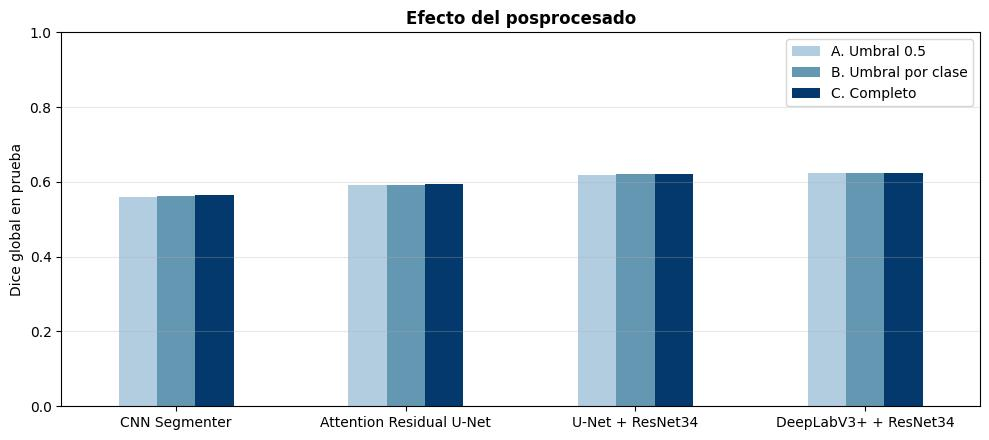

,A. Umbral 0.5,B. Umbral por clase,C. Completo
CNN Segmenter,0.5608,0.5624,0.5652
Attention Residual U-Net,0.5909,0.5923,0.5942
U-Net + ResNet34,0.6191,0.6199,0.6201
DeepLabV3+ + ResNet34,0.6245,0.6242,0.6243


In [6]:
variantes = pd.DataFrame({MODELOS[m]: [promedio(conteos[m][f"test_{v}"], METRICA_PRINCIPAL) for v in "ABC"]
                          for m in resumenes}, index=["A. Umbral 0.5", "B. Umbral por clase", "C. Completo"]).T
fig, ax = plt.subplots(figsize=(10, 4.5))
variantes.plot.bar(ax=ax, rot=0, color=["#b3cde0", "#6497b1", "#03396c"])
ax.set_ylabel(f"{NOMBRE_METRICA} en prueba")
ax.set_ylim(0, 1)
ax.set_title("Efecto del posprocesado", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "comparacion_posproceso.png", dpi=120)
plt.show()
variantes.round(4)

## 7. ¿Las diferencias son reales? Bootstrap
Con 555 imágenes de prueba, dos modelos pueden quedar separados por una diferencia que es solo ruido. Para medirlo se remuestrean las imágenes de prueba con reemplazo 1000 veces (las mismas imágenes para todos los modelos en cada réplica) y se recalcula la métrica.

- El intervalo del 95 % de cada modelo va del percentil 2.5 al 97.5 de las réplicas.
- La diferencia con el mejor modelo de validación se calcula réplica a réplica. Si su intervalo no incluye el cero, la diferencia es consistente y no se explica por las imágenes que tocaron en prueba.

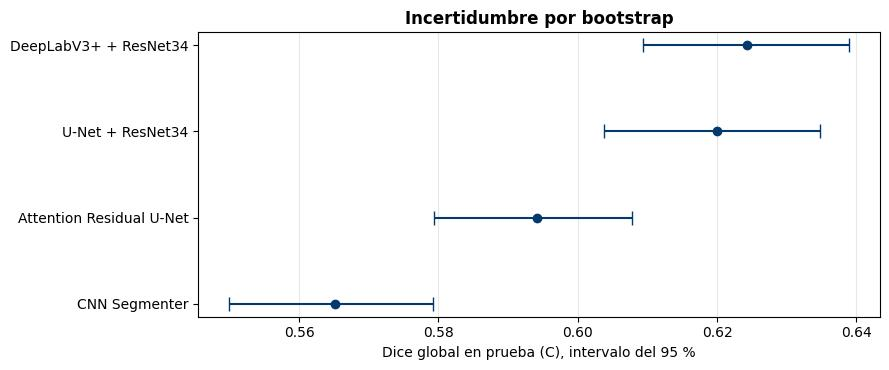

,Prueba (C),IC 2.5 %,IC 97.5 %,Diferencia con DeepLabV3+ + ResNet34,Dif. IC 2.5 %,Dif. IC 97.5 %,% réplicas en que gana DeepLabV3+ + ResNet34
CNN Segmenter,0.5652,0.5500,0.5792,0.0591,0.0507,0.0682,100.0
Attention Residual U-Net,0.5942,0.5794,0.6078,0.0302,0.0232,0.0372,100.0
U-Net + ResNet34,0.6201,0.6037,0.6348,0.0044,-0.0004,0.0088,95.8
DeepLabV3+ + ResNet34,0.6243,0.6093,0.6389,0.0000,0.0000,0.0000,0.0


In [7]:
boot = bootstrap({m: conteos[m]["test_C"] for m in resumenes}, METRICA_PRINCIPAL, n=1000)
val_c = {m: promedio(conteos[m]["val_C"], METRICA_PRINCIPAL) for m in resumenes}
mejor_val = max(val_c, key=val_c.get)

intervalos = pd.DataFrame({
    "Prueba (C)": {m: promedio(conteos[m]["test_C"], METRICA_PRINCIPAL) for m in resumenes},
    "IC 2.5 %": boot.quantile(0.025),
    "IC 97.5 %": boot.quantile(0.975),
    f"Diferencia con {MODELOS[mejor_val]}": {m: (boot[mejor_val] - boot[m]).mean() for m in resumenes},
    "Dif. IC 2.5 %": {m: (boot[mejor_val] - boot[m]).quantile(0.025) for m in resumenes},
    "Dif. IC 97.5 %": {m: (boot[mejor_val] - boot[m]).quantile(0.975) for m in resumenes},
    f"% réplicas en que gana {MODELOS[mejor_val]}": {m: 100 * (boot[mejor_val] > boot[m]).mean() for m in resumenes},
})
intervalos.index = [MODELOS[m] for m in intervalos.index]
intervalos.to_csv(ARTIFACTS_DIR / "bootstrap.csv")

fig, ax = plt.subplots(figsize=(9, 3.8))
orden = intervalos.sort_values("Prueba (C)")
ax.errorbar(orden["Prueba (C)"], orden.index, fmt="o", color="#03396c", capsize=5,
            xerr=[orden["Prueba (C)"] - orden["IC 2.5 %"], orden["IC 97.5 %"] - orden["Prueba (C)"]])
ax.set_xlabel(f"{NOMBRE_METRICA} en prueba (C), intervalo del 95 %")
ax.set_title("Incertidumbre por bootstrap", fontweight="bold")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "comparacion_bootstrap.png", dpi=120)
plt.show()
intervalos.round(4)

## 8. Elección del campeón
El resultado queda en `artifacts/champion.json`, que es lo único que lee la app.

In [8]:
if CHAMPION_MANUAL is not None:
    assert CHAMPION_MANUAL in resumenes, f"{CHAMPION_MANUAL} no tiene resultados. Opciones: {list(resumenes)}"
campeon = CHAMPION_MANUAL or mejor_val
criterio = ("manual" if CHAMPION_MANUAL else
            f"automático: mayor {NOMBRE_METRICA} en validación con posprocesado completo (variante C)")

champion = {
    "modelo": campeon,
    "nombre": MODELOS[campeon],
    "criterio": criterio,
    "metrica": METRICA_PRINCIPAL,
    "validacion": round(val_c[campeon], 4),
    "prueba": round(promedio(conteos[campeon]["test_C"], METRICA_PRINCIPAL), 4),
    "pesos": f"artifacts/{campeon}/pesos_fp16.pt",
    "posproceso": f"artifacts/{campeon}/posproceso.json",
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M"),
}
CHAMPION_JSON.write_text(json.dumps(champion, indent=2, ensure_ascii=False))
print(f"Campeón: {champion['nombre']} ({criterio})")
champion

Campeón: DeepLabV3+ + ResNet34 (automático: mayor Dice global en validación con posprocesado completo (variante C))


{'modelo': 'deeplab_r34',
 'nombre': 'DeepLabV3+ + ResNet34',
 'criterio': 'automático: mayor Dice global en validación con posprocesado completo (variante C)',
 'metrica': 'dice',
 'validacion': 0.6151,
 'prueba': 0.6243,
 'pesos': 'artifacts/deeplab_r34/pesos_fp16.pt',
 'posproceso': 'artifacts/deeplab_r34/posproceso.json',
 'fecha': '2026-11-18 04:51'}

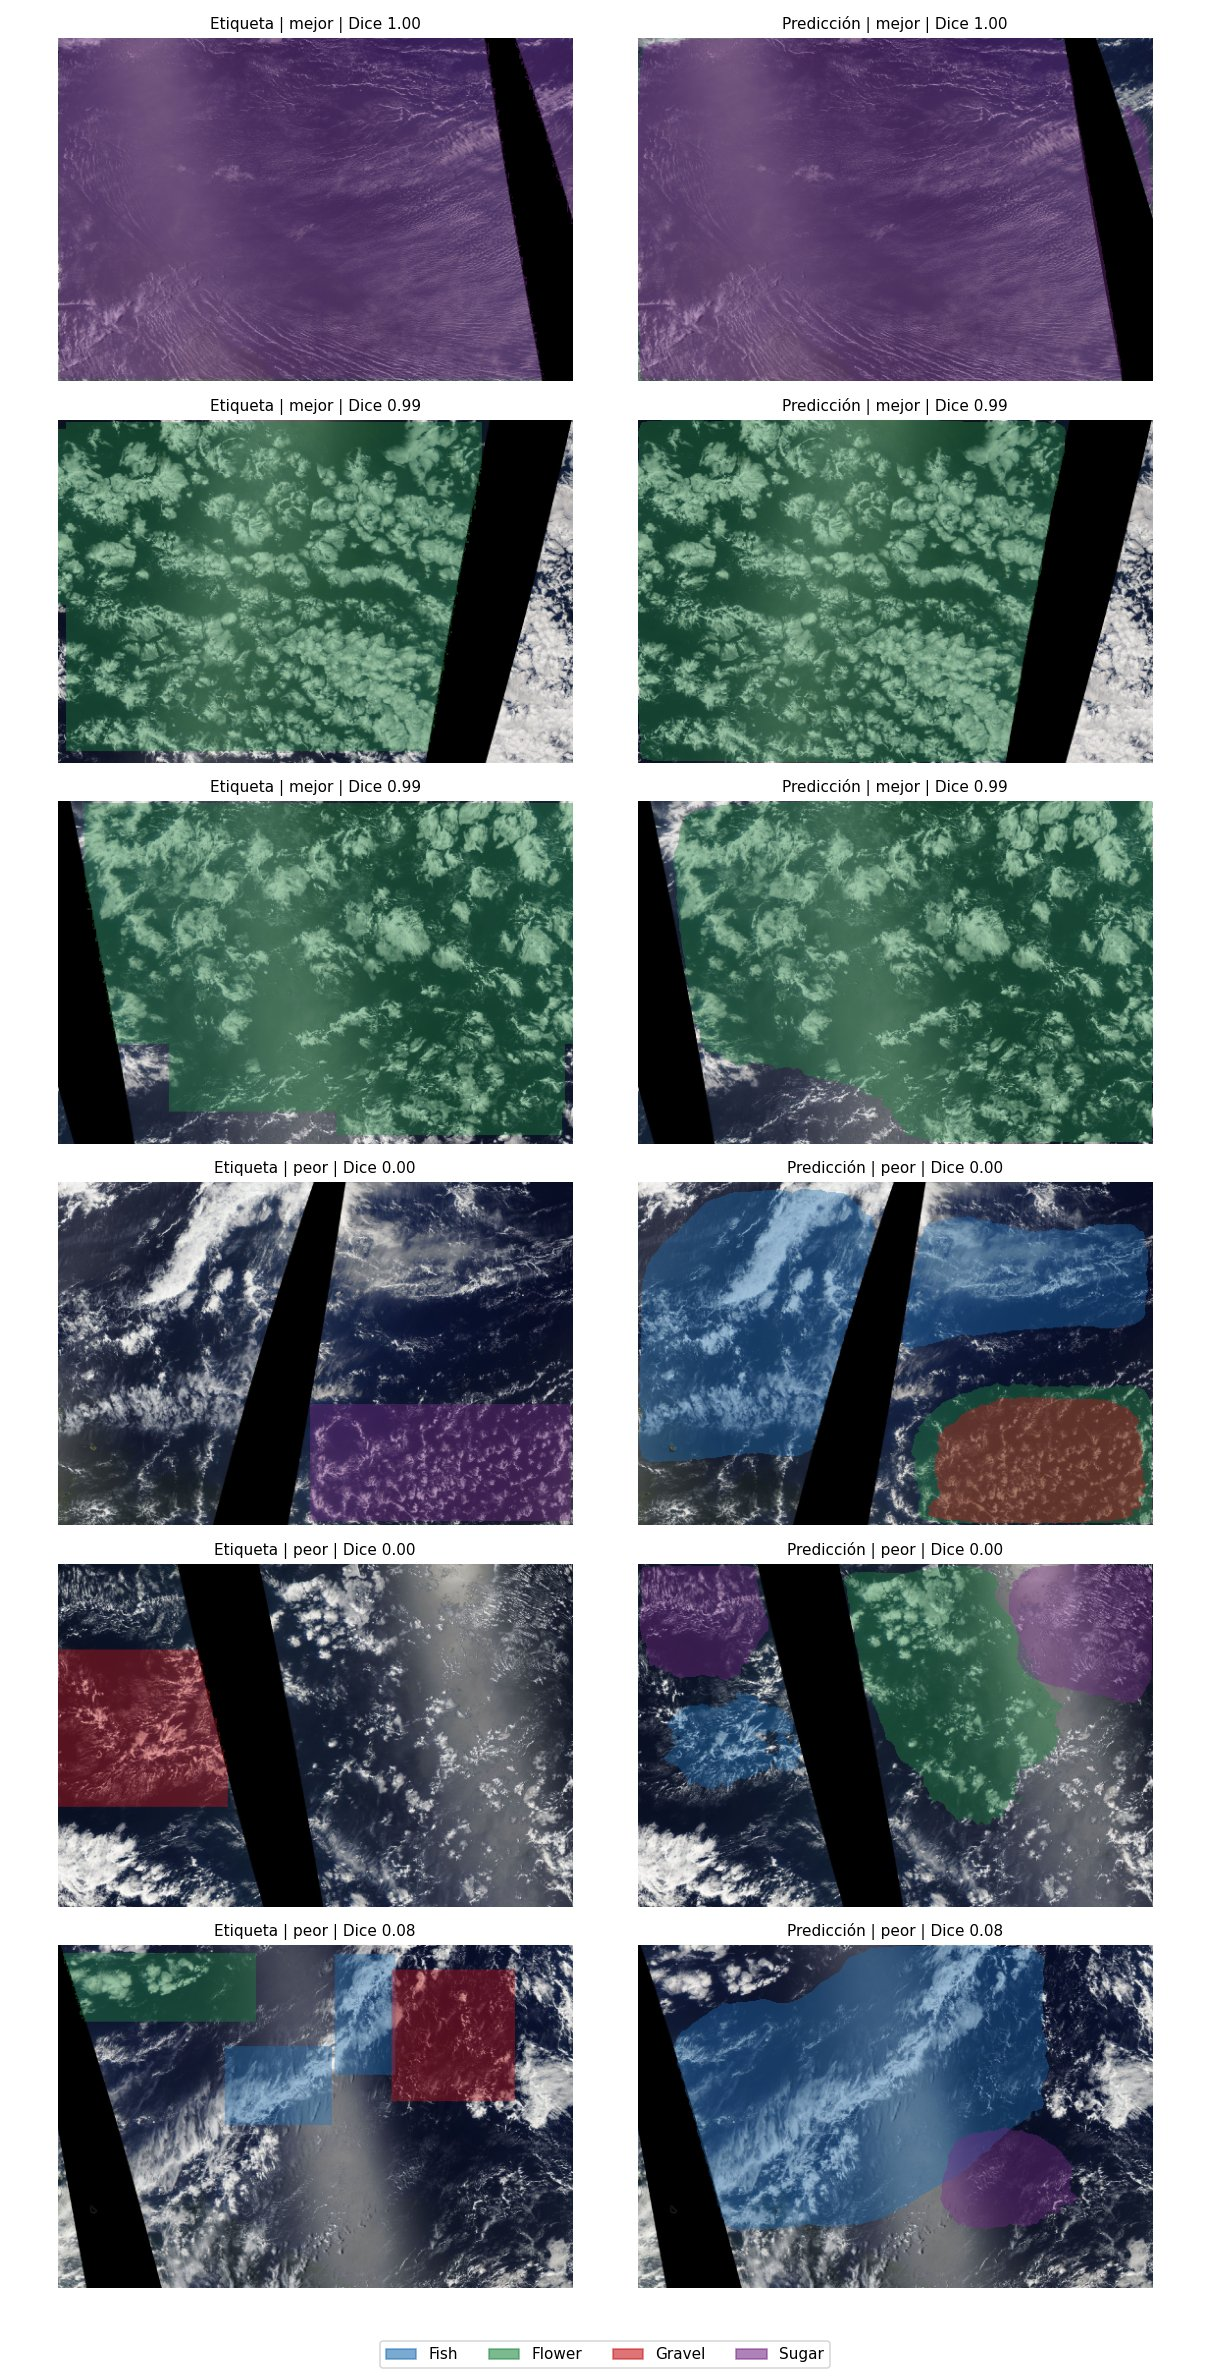

In [9]:
display(Image(filename=str(ARTIFACTS_DIR / campeon / "ejemplos.jpg")))

## 9. Resumen de la comparación

In [10]:
ranking = comparacion[f"{NOMBRE_METRICA} validación (C)"]
print(f"Ranking por {NOMBRE_METRICA} en validación (C):")
for i, (modelo, valor) in enumerate(ranking.items(), 1):
    prueba = comparacion.loc[modelo, f"{NOMBRE_METRICA} prueba (C)"]
    print(f"  {i}. {modelo:28s} validación {valor:.4f} | prueba {prueba:.4f}")
print()
for m in resumenes:
    if m == mejor_val:
        continue
    fila = intervalos.loc[MODELOS[m]]
    consistente = fila["Dif. IC 2.5 %"] > 0
    print(f"{MODELOS[mejor_val]} frente a {MODELOS[m]}: diferencia de {fila.iloc[3]:+.4f} en prueba, "
          f"{'consistente' if consistente else 'no concluyente'} según el bootstrap "
          f"(gana en el {fila.iloc[6]:.0f} % de las réplicas)")
print(f"\nCampeón desplegado: {champion['nombre']} ({champion['criterio']})")

Ranking por Dice global en validación (C):
  1. DeepLabV3+ + ResNet34        validación 0.6151 | prueba 0.6243
  2. U-Net + ResNet34             validación 0.6119 | prueba 0.6201
  3. Attention Residual U-Net     validación 0.5808 | prueba 0.5942
  4. CNN Segmenter                validación 0.5532 | prueba 0.5652

DeepLabV3+ + ResNet34 frente a CNN Segmenter: diferencia de +0.0591 en prueba, consistente según el bootstrap (gana en el 100 % de las réplicas)
DeepLabV3+ + ResNet34 frente a Attention Residual U-Net: diferencia de +0.0302 en prueba, consistente según el bootstrap (gana en el 100 % de las réplicas)
DeepLabV3+ + ResNet34 frente a U-Net + ResNet34: diferencia de +0.0044 en prueba, no concluyente según el bootstrap (gana en el 96 % de las réplicas)

Campeón desplegado: DeepLabV3+ + ResNet34 (automático: mayor Dice global en validación con posprocesado completo (variante C))
